# Wine (scikit-learn): clustering

178 wines from three cultivars, 13 chemical measurements (scikit-learn copy of the UCI table), standardized. The three cultivars are the reference labels (report dataset D6).

Every method is tuned by the shared, label-free rule (`sc4020.tuning`); labels are used only for the
external scores. Sections: dataset loading, one section per method, metrics, visualization. Tables go to
`results/datasets/wine_results.csv` and `wine_tuning.csv`, figures to `results/datasets/figures/`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sc4020 import run, tuning
from sc4020.datasets import load_dataset

warnings.filterwarnings("ignore")
np.random.seed(run.SEED)

DATASET_NAME = "wine"
TOPIC = "datasets"
MAX_CLUSTERS = None  # optional cap on the number of DBSCAN and HDBSCAN clusters

## 1. Dataset loading

In [2]:
ds = load_dataset(DATASET_NAME)
k_range = run.K_RANGES.get(DATASET_NAME, tuning.K_RANGE)
print(ds.DESCR)
print(f"{len(ds.data):,} points, {ds.data.shape[1]} features, classes: {ds.n_true_clusters}")
pd.DataFrame(ds.data, columns=ds.feature_names).describe().round(2)

UCI Wine (scikit-learn copy): 178 x 13, 3 cultivars. Features standardized.
178 points, 13 features, classes: 3


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.43,-1.43,-3.68,-2.67,-2.09,-2.11,-1.70,-1.87,-2.07,-1.63,-2.09,-1.90,-1.49
25%,-0.79,-0.66,-0.57,-0.69,-0.82,-0.89,-0.83,-0.74,-0.60,-0.80,-0.77,-0.95,-0.78
50%,0.06,-0.42,-0.02,0.00,-0.12,0.10,0.11,-0.18,-0.06,-0.16,0.03,0.24,-0.23
75%,0.84,0.67,0.70,0.60,0.51,0.81,0.85,0.61,0.63,0.49,0.71,0.79,0.76
max,2.26,3.11,3.16,3.15,4.37,2.54,3.06,2.40,3.49,3.44,3.30,1.96,2.97


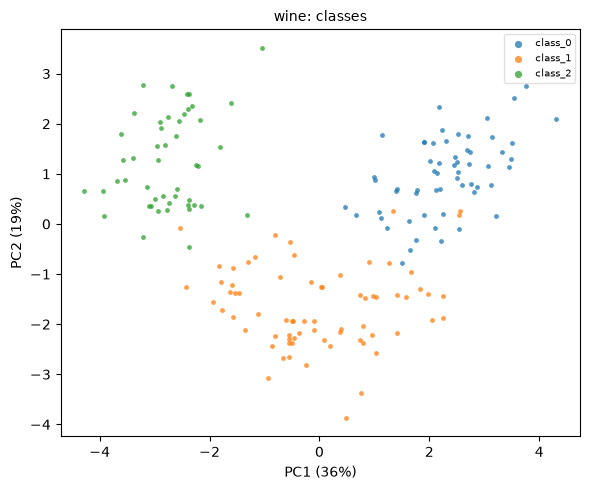

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/wine_data.png')

In [3]:
from sc4020.generate_figures import plot_coords, scatter_labels, show_and_save

x, y, x_label, y_label = plot_coords(ds)
fig, ax = plt.subplots(figsize=(6, 5))
scatter_labels(
    ax,
    np.column_stack([x, y]),
    ds.target,
    title=f"{DATASET_NAME}: {'classes' if ds.target is not None else 'points'}",
    class_names=ds.get("target_names"),
    size=2 if len(ds.data) > 5000 else 12,
)
ax.set_xlabel(x_label)
ax.set_ylabel(y_label)
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_data")

## 2. Clustering with K-Means

The number of clusters k comes from the fake-data check: for each k, the silhouette on the real data
minus the mean silhouette on copies with every column shuffled, among the k whose seeds agree. On
labelled data K-Means uses the true number of classes, and the label-free choice is shown next to it.
Plain K-Means starts from random centres; K-Means++ (next section) uses the same k.

In [4]:
selections, results = {}, {}
selections["K-Means"] = run.select_method(ds, "K-Means", k_range=k_range)
kmeans_tried = pd.DataFrame(selections["K-Means"].tried)
label_free_k = selections["K-Means"].label_free["n_clusters"]
print(f"k used: {selections['K-Means'].params['n_clusters']}, label-free choice: {label_free_k}")
kmeans_tried.round(3)

k used: 3, label-free choice: 3


,n_clusters,inertia,silhouette,null_silhouette,null_gap,davies_bouldin,smallest_cluster,largest_cluster,mean_seed_ari,min_seed_ari,ari
0,2,1658.759,0.259,0.074,0.185,1.526,87,91,0.766,0.498,0.374
1,3,1277.928,0.285,0.065,0.220,1.389,51,65,1.000,1.000,0.897
2,4,1175.428,0.260,0.064,0.196,1.797,29,55,0.905,0.686,0.765
3,5,1109.513,0.202,0.068,0.134,1.808,26,59,0.734,0.553,0.599
4,6,1046.002,0.237,0.073,0.164,1.554,5,53,0.675,0.461,0.639
5,7,981.595,0.204,0.074,0.129,1.661,3,54,0.632,0.450,0.566
6,8,935.201,0.157,0.070,0.087,1.741,3,39,0.608,0.479,0.415
7,9,889.893,0.150,0.073,0.077,1.708,4,34,0.576,0.471,0.385
8,10,845.895,0.144,0.071,0.073,1.707,4,27,0.602,0.463,0.344


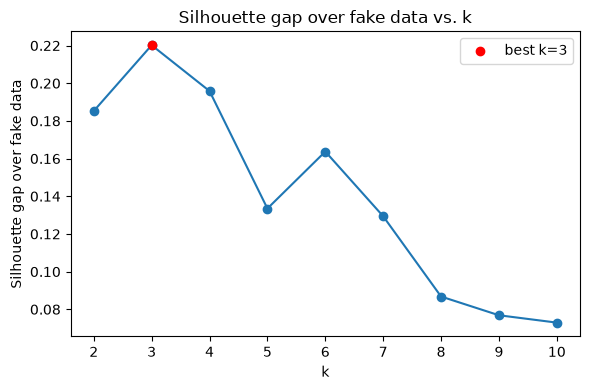

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/wine_kmeans_k_selection.png')

In [5]:
from sc4020.generate_figures import plot_k_selection, show_and_save

fig = plot_k_selection(
    kmeans_tried["n_clusters"].tolist(),
    kmeans_tried["null_gap"].tolist(),
    best_k=label_free_k,
    ylabel="Silhouette gap over fake data",
)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_kmeans_k_selection")

In [6]:
selections["K-Means (random init)"] = run.select_method(ds, "K-Means (random init)", selections)
results["K-Means (random init)"] = run.fit_method(
    ds, "K-Means (random init)", selections["K-Means (random init)"]
)

## 3. Clustering with K-Means++

In [7]:
results["K-Means"] = run.fit_method(ds, "K-Means", selections["K-Means"])
pd.DataFrame(
    {
        name: {
            "inertia": results[name].model.inertia_,
            "iterations": results[name].model.n_iter_,
            "fit_seconds": results[name].fit_seconds,
        }
        for name in ("K-Means (random init)", "K-Means")
    }
).T.round(3)

,inertia,iterations,fit_seconds
K-Means (random init),1277.928,7.0,0.005
K-Means,1277.928,7.0,0.006


## 4. Clustering with DBSCAN

min_samples follows the dimension, and eps is tried at multiples of the knee of the k-distance curve.
The rule keeps settings with at least 2 clusters and at most half the points as noise, then takes the
highest silhouette.

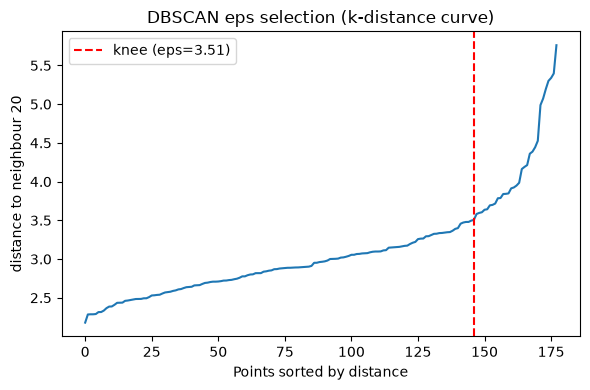

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/wine_dbscan_k_distance.png')

In [8]:
from sc4020.generate_figures import plot_k_distance, show_and_save

min_samples = tuning.min_samples_from_dimension(ds.data.shape[1])
curve = tuning.k_distance_curve(ds.data, min_samples)
knee_index, eps_at_knee = tuning.find_knee(curve)
fig = plot_k_distance(curve, knee_index, eps_at_knee, min_samples)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_dbscan_k_distance")

In [9]:
selections["DBSCAN"] = run.select_method(ds, "DBSCAN", max_clusters=MAX_CLUSTERS)
results["DBSCAN"] = run.fit_method(ds, "DBSCAN", selections["DBSCAN"])
print(f"chosen: {run.format_params(selections['DBSCAN'].params)}, rule satisfied: {selections['DBSCAN'].valid}")
pd.DataFrame(selections["DBSCAN"].tried).round(3)

chosen: eps=3.09, min_samples=40, rule satisfied: True


,eps,min_samples,eps_factor,n_clusters,noise_fraction,largest_cluster_share,silhouette,ari,passes
0,1.554,10,0.50,0,1.000,0.000,NaN,0.000,False
1,2.331,10,0.75,2,0.337,0.494,0.356,0.296,True
2,3.108,10,1.00,1,0.051,0.949,NaN,-0.007,False
3,1.753,20,0.50,0,1.000,0.000,NaN,0.000,False
4,2.629,20,0.75,2,0.292,0.494,0.352,0.351,True
5,3.506,20,1.00,1,0.051,0.949,NaN,-0.007,False
6,2.057,40,0.50,0,1.000,0.000,NaN,0.000,False
7,3.085,40,0.75,2,0.236,0.534,0.365,0.431,True
8,4.114,40,1.00,1,0.022,0.978,NaN,-0.006,False
9,2.674,80,0.50,0,1.000,0.000,NaN,0.000,False


## 5. Clustering with HDBSCAN

In [10]:
selections["HDBSCAN"] = run.select_method(ds, "HDBSCAN", max_clusters=MAX_CLUSTERS)
results["HDBSCAN"] = run.fit_method(ds, "HDBSCAN", selections["HDBSCAN"])
print(f"chosen: {run.format_params(selections['HDBSCAN'].params)}, rule satisfied: {selections['HDBSCAN'].valid}")
pd.DataFrame(selections["HDBSCAN"].tried).round(3)

chosen: min_cluster_size=5, min_samples=10, rule satisfied: True


,min_cluster_size,min_samples,n_clusters,noise_fraction,largest_cluster_share,silhouette,ari,passes
0,5,NaN,2,0.326,0.483,0.352,0.342,True
1,5,5.0,2,0.326,0.483,0.352,0.342,True
2,5,10.0,2,0.421,0.421,0.363,0.260,True
3,10,NaN,2,0.421,0.421,0.363,0.260,True
4,10,5.0,2,0.326,0.483,0.352,0.342,True
5,10,10.0,2,0.421,0.421,0.363,0.260,True
6,15,NaN,2,0.461,0.416,0.349,0.228,True
7,15,5.0,2,0.326,0.483,0.352,0.342,True
8,15,10.0,2,0.421,0.421,0.363,0.260,True


## 6. Clustering with GMM

The number of components and the covariance type with the lowest BIC (the number of components is the
number of classes on labelled data).

In [11]:
selections["GMM"] = run.select_method(ds, "GMM", k_range=k_range)
results["GMM"] = run.fit_method(ds, "GMM", selections["GMM"])
gmm_tried = pd.DataFrame(selections["GMM"].tried).rename(columns={"score": "minus_bic"})
print(f"chosen: {run.format_params(selections['GMM'].params)}, label-free: {run.format_params(selections['GMM'].label_free)}")
gmm_tried.pivot(index="n_components", columns="covariance_type", values="minus_bic").round(1)

chosen: n_components=3, covariance_type=diag, label-free: n_components=4, covariance_type=diag


covariance_type,diag,full,spherical,tied
n_components,,,,
2,-5983.7,-5629.6,-6135.0,-5644.7
3,-5543.4,-5806.3,-5708.8,-5572.6
4,-5478.7,-5806.8,-5645.8,-5529.9
5,-5544.7,-6360.4,-5649.7,-5547.5
6,-5560.9,-6752.7,-5634.4,-5556.2
7,-5604.1,-6709.9,-5663.7,-5570.8
8,-5679.1,-6407.9,-5672.1,-5530.9
9,-5656.3,-6448.7,-5684.5,-5524.3
10,-5780.3,-6645.4,-5685.6,-5557.0


## 7. Clustering with Spectral

Spectral clustering at the K-Means k: an RBF affinity on Wine, a 10-nearest-neighbour graph elsewhere
(`run.SPECTRAL_AFFINITY_BY_DATASET`). A dense RBF affinity needs memory quadratic in the number of
points, so it is skipped on large data; the nearest-neighbour graph is sparse and runs at any size.

In [12]:
if run.is_too_large(ds, "Spectral"):
    print(f"skipping Spectral: {len(ds.data):,} points is above {run.MAX_POINTS_FOR_DENSE_SPECTRAL:,}")
else:
    selections["Spectral"] = run.select_method(ds, "Spectral", selections)
    results["Spectral"] = run.fit_method(ds, "Spectral", selections["Spectral"])
    print(f"Spectral: {run.format_params(selections['Spectral'].params)}")

Spectral: n_clusters=3, affinity=rbf


## 8. Metrics

Internal scores (silhouette, Davies-Bouldin, DBCV) need no labels; ARI and NMI compare with the classes
when there are any. Noise points are left out of the internal scores. The null columns refit each
method at its setting on a copy with every column shuffled: a silhouette near the null one means the
clusters are no stronger than on data without structure.

In [13]:
table = run.score_methods(ds, selections, results)
run.save_dataset_run(DATASET_NAME, table, run.tried_settings(ds, selections))
columns = [
    "method",
    "params",
    "n_clusters",
    "noise_fraction",
    "largest_cluster_share",
    "silhouette",
    "davies_bouldin",
    "dbcv",
    "ari",
    "nmi",
    "fit_seconds",
    "null_silhouette",
]
table[[column for column in columns if column in table]].round(3)

,method,params,n_clusters,noise_fraction,largest_cluster_share,silhouette,davies_bouldin,dbcv,ari,nmi,fit_seconds,null_silhouette
0,K-Means (random init),n_clusters=3,3,0.000,0.365,0.285,1.389,-0.274,0.897,0.876,0.005,0.066
1,K-Means,n_clusters=3,3,0.000,0.365,0.285,1.389,-0.274,0.897,0.876,0.006,0.066
2,DBSCAN,"eps=3.09, min_samples=40",2,0.236,0.534,0.365,1.080,0.112,0.431,0.536,0.001,NaN
3,HDBSCAN,"min_cluster_size=5, min_samples=10",2,0.421,0.421,0.363,1.046,0.121,0.260,0.354,0.002,NaN
4,GMM,"n_components=3, covariance_type=diag",3,0.000,0.393,0.280,1.412,-0.292,0.915,0.892,0.007,0.054
5,Spectral,"n_clusters=3, affinity=rbf",3,0.000,0.680,0.249,1.271,-0.211,0.445,0.572,0.009,0.011


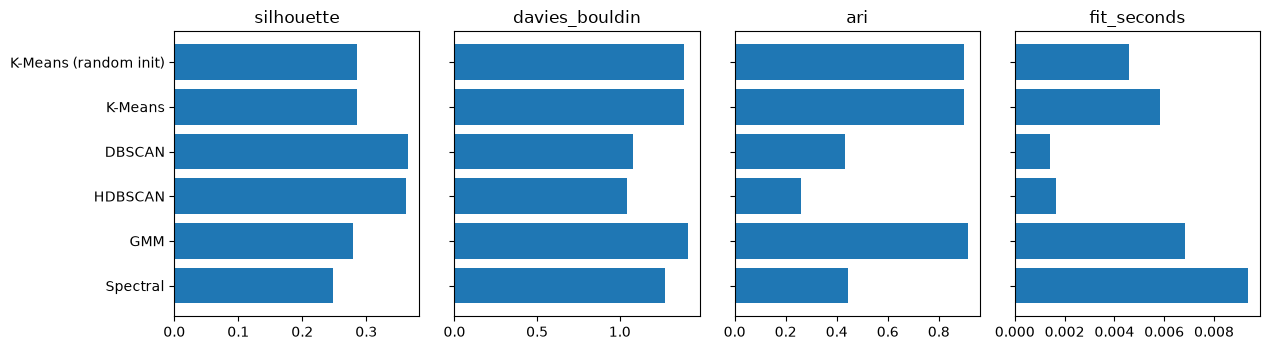

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/wine_metrics.png')

In [14]:
from sc4020.generate_figures import show_and_save

metric_names = [m for m in ("silhouette", "davies_bouldin", "ari", "fit_seconds") if m in table]
fig, axes = plt.subplots(1, len(metric_names), figsize=(3.2 * len(metric_names), 3.6), sharey=True)
for ax, metric in zip(axes, metric_names):
    ax.barh(table["method"], table[metric])
    ax.set_title(metric)
axes[0].invert_yaxis()
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_metrics")

## 9. Visualization

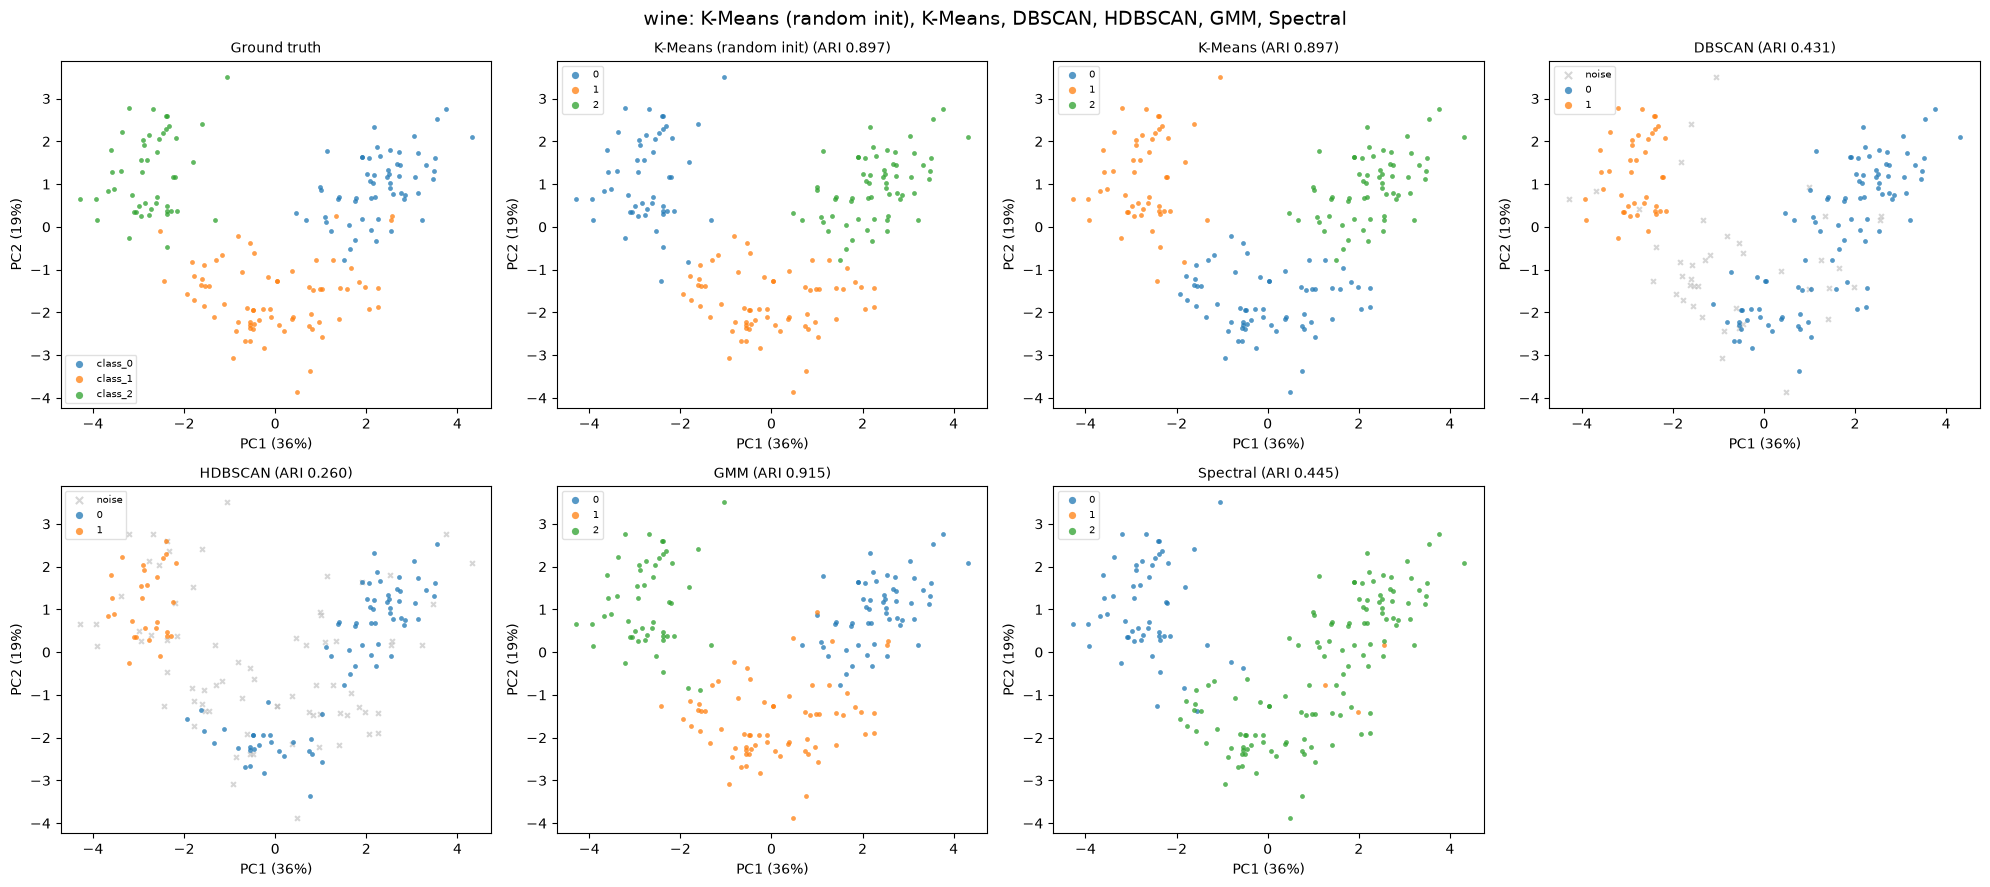

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/wine_clusters.png')

In [15]:
from sc4020.generate_figures import show_and_save

fig = run.plot_dataset(ds, results, table, title=f"{DATASET_NAME}: {', '.join(results)}")
show_and_save(fig, TOPIC, f"{DATASET_NAME}_clusters")